## Packages

In [67]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp   
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import (train_test_split,KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)
import pandas as pd

In [2]:
from Structure.Act_Cost import *
from Structure.DataProcess import Data_process
from Structure.NeuralNetwork import NeuralNetwork 
from Structure.Optimizer import Optimizer
from Structure.SGD import step_length, train_sgd
from Structure.PGD import train_plain
from Structure.NeuralNetRegressor import NeuralNetRegressor

## Data

(100, 1) (100, 1)


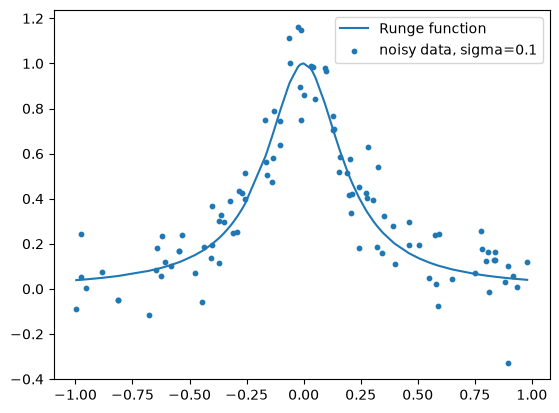

In [3]:
np.random.seed(2026)

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100 # 350 in Project 1
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1 # 0.25 in Project 1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
Y = y.reshape(-1, 1)  # make y a column vector for the network
print(X.shape, Y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

In [4]:
from Structure.Act_Cost import *
from Structure.DataProcess import Data_process
from Structure.NeuralNetwork import NeuralNetwork 
from Structure.Optimizer import Optimizer
from Structure.SGD import step_length, train_sgd
from Structure.PGD import train_plain
from Structure.NeuralNetRegressor import NeuralNetRegressor

## Analysis and comparison of model


### LLM Declaration:
Exercices week44


In [ ]:
X, y = Data_process(x, y, Process="Scale")
set_epoch = 10

cv = KFold(n_splits=5, shuffle=True, random_state=2026)
net = make_pipeline(StandardScaler(), NeuralNetRegressor(
        hidden=(50,), activation="sigmoid", 
        gamma=0.01, lmbd = 0.0, penalty=None, method = "plain", 
        epochs=set_epoch, batch_size=10, 
        descent = "sgd", seed=2026))


scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)

In [6]:
print("-cross_val_score:")
print(f"5-fold CV MSE {scores.mean():.4f} +/- {scores.std(ddof=1) / np.sqrt(len(scores)):.4f}")
print(f"folds: {scores}")
print("cross_validate:")
#print(res)
validation_mse = -res["test_score"]
training_mse = -res["train_score"]
print("5 Fold Test score:", validation_mse)
print("5 Fold train score:", training_mse)

mean_mse = validation_mse.mean()
std_error = validation_mse.std(ddof=1) / np.sqrt(len(validation_mse))

print(f"CV MSE: {mean_mse:.4f} +/- {std_error:.4f}")

print("The MSE is an approximate standard error of the mean MSE, since the folds in the training sets overlap, the scores are not independent")

-cross_val_score:
5-fold CV MSE 0.1042 +/- 0.0104
folds: [0.13391762 0.12027428 0.0775121  0.10204228 0.08727936]
cross_validate:
5 Fold Test score: [0.13391762 0.12027428 0.0775121  0.10204228 0.08727936]
5 Fold train score: [0.09098394 0.09747383 0.10456038 0.09928787 0.10045139]
CV MSE: 0.1042 +/- 0.0104
The MSE is an approximate standard error of the mean MSE, since the folds in the training sets overlap, the scores are not independent


# Learning rate and Method with GridSearchCV
- (50, ) vS (50, 100, )
* Learning Rates $\gamma$
* SGD: RMS, Adam, Plain
* PGD. 

Choose best model (One SE Rule):

A problem here is that for descent = "plain" the code 
 omits the method parameter, since the method is only used for SGD. 
 This means that the grid search will not test all combinations of 
 method and descent, which may lead to suboptimal results. 
 A possible solution is to create a custom estimator that 
 takes both method and descent as parameters, and then use that estimator in the grid search.
 ## Error
 Invalid parameter 'descent' for estimator NeuralNetRegressor(). Valid parameters are: ['activation', 'batch_size', 'epochs', 'gamma', 'hidden', 'lmbd', 'method', 'penalty', 'seed']

In [68]:
param_grid = {"neuralnetregressor__gamma": [0.001, 0.003, 0.01, 0.03, 0.1],
            "neuralnetregressor__method": ["rmsprop", "adam", "plain"],
            "neuralnetregressor__hidden": [(50,), (50, 100,)]}

search1 = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
search1.fit(X, y)

KeyboardInterrupt: 

In [49]:
results = search1.cv_results_          # a dict of arrays, one entry per grid point
results_df = pd.DataFrame({
    "Activation": [
        p["neuralnetregressor__gamma"] for p in results["params"]
    ],
    "Method": [
        p["neuralnetregressor__method"] for p in results["params"]
    ],
    "Hidden layers": [
        p["neuralnetregressor__hidden"] for p in results["params"]
    ],
    # Scoringen er negativ MSE; snu fortegnet for å få positiv MSE.
    "Mean CV MSE": -results["mean_test_score"],
    "Std CV MSE": results["std_test_score"],
    "Mean fit time (s)": results["mean_fit_time"],
})

display(results_df.sort_values("Mean CV MSE").reset_index(drop=True))

,Activation,Method,Hidden layers,Mean CV MSE,Std CV MSE,Mean fit time (s)
0,0.100,adam,"(50, 100)",0.017822,0.002011,3.783603
1,0.030,adam,"(50, 100)",0.017885,0.002712,3.280360
2,0.010,adam,"(50, 100)",0.018065,0.002770,3.239470
3,0.010,adam,"(50,)",0.018463,0.003024,1.896706
4,0.003,adam,"(50, 100)",0.019957,0.003203,3.317861
5,0.030,rmsprop,"(50, 100)",0.022913,0.006340,3.355779
6,0.030,adam,"(50,)",0.023416,0.010491,1.847507
7,0.010,rmsprop,"(50, 100)",0.024179,0.009194,3.208208
8,0.003,rmsprop,"(50,)",0.027679,0.006000,1.990952
9,0.003,adam,"(50,)",0.028000,0.006111,1.863094


#### LLM Declaration
Used Copilot and Codex with GPT-Sol 6.1 to use dictionaries 
and find + store the best One-SE limit

In [ ]:
cv_mse_grid = -results["mean_test_score"]
cv_se_grid = results["std_test_score"] / np.sqrt(cv.get_n_splits() - 1)

#print("mse grid")
#print(cv_mse_grid)
#print("se grid")
#print(cv_se_grid)
print("-----")
best_estimator = search1.best_estimator_
best_params = search1.best_params_
print(best_estimator)
print(best_params)
print("-----")
print("Final Result:\n")
best_mse = -search1.best_score_  # Ved scoring="neg_mean_squared_error"
best_index = search1.best_index_
k = search1.n_splits_
best_se = search1.cv_results_["std_test_score"][best_index] / np.sqrt(k - 1)
best_gamma = best_params["neuralnetregressor__gamma"]
best_method = best_params["neuralnetregressor__method"]
best_hidden = best_params["neuralnetregressor__hidden"]

print(f"best_mse = {best_mse:.4f} +/- best_se = {best_se:.4f}")
print(f"gamma = {best_gamma}") 
print(f"method = {best_method}")
print(f"hidden = {best_hidden}")
print("-------")

"AI Declaration: GPT-Luna6 help with indexing and for loop"
threshold = cv_mse_grid[best_index] + cv_se_grid[best_index]
print(f"One-SE limit:  {threshold:.5f}\n")


found = False
One_SE_candidates = {}
for i, params in enumerate(results["params"]):
    gamma = params["neuralnetregressor__gamma"]
    method = params["neuralnetregressor__method"]
    hidden = params["neuralnetregressor__hidden"]
    lmbd = 0.0  # Assuming lambda is not part of the grid
    if (cv_mse_grid[i] <= threshold and sum(hidden) < sum(best_hidden)):
        found = True
        print(
            f"gamma={gamma:g} "
            f"method={method},hidden={hidden}, "
            f"CV-MSE={cv_mse_grid[i]:.5f} +/- {cv_se_grid[i]:.5f}"
        )
        One_SE_candidates[(method, tuple(hidden), gamma)] = cv_mse_grid[i]
        best_key = min(One_SE_candidates, key=One_SE_candidates.get)
        best_mse = One_SE_candidates[best_key]

        print(f"One-SE best architecture: method={best_key[0]}, hidden={best_key[1]}, gamma={best_key[2]:g}, CV-MSE={best_mse:.5f}")
if not found:
    print("No architecture gave a CV-MSE within one SE of the lowest.")


-----
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(epochs=100, gamma=0.1, hidden=(50, 100),
                                    method='adam'))])
{'neuralnetregressor__gamma': 0.1, 'neuralnetregressor__hidden': (50, 100), 'neuralnetregressor__method': 'adam'}
-----
Final Result:

best_mse = 0.0178 +/- best_se = 0.0010
gamma = 0.1
method = adam
hidden = (50, 100)
-------
One-SE limit:  0.01883

gamma=0.01 method=adam,hidden=(50,), CV-MSE=0.01846 +/- 0.00151
One-SE best architecture: method=adam, hidden=(50,), gamma=0.01, CV-MSE=0.01846


#### LLM Declaration:
Codex GPT-Sol 6.1 used to generate the Heatmap of the results with 1-SE limit and lowest MSE of all 1-SE candidates.

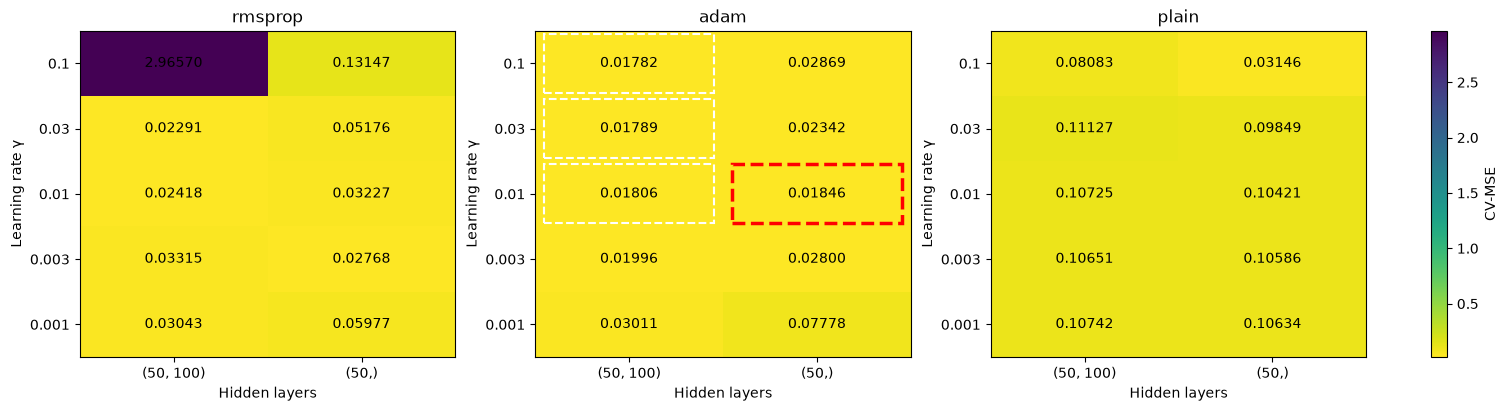

In [11]:
results = search1.cv_results_
best_index = search1.best_index_
best_mse = -results["mean_test_score"][best_index]
best_se = (
    results["std_test_score"][best_index]
    / np.sqrt(search1.n_splits_ - 1)
)
threshold = best_mse + best_se
selected_key = min(One_SE_candidates, key=One_SE_candidates.get)
selected_method, selected_hidden, selected_gamma = selected_key

df = pd.DataFrame([
    {
        "method": p["neuralnetregressor__method"],
        "hidden": str(p["neuralnetregressor__hidden"]),
        "gamma": p["neuralnetregressor__gamma"],
        "MSE": -score,
    }
    for p, score in zip(
        results["params"], results["mean_test_score"]
    )
])

methods = df["method"].unique()
fig, axes = plt.subplots(
    1, len(methods),
    figsize=(5 * len(methods), 4),
    squeeze=False,
    constrained_layout=True,
)

for ax, method in zip(axes[0], methods):
    grid = df[df["method"] == method].pivot(
        index="gamma", columns="hidden", values="MSE"
    ).sort_index()

    im = ax.imshow(
        grid.values,
        origin="lower",
        aspect="auto",
        cmap="viridis_r",
        vmin=df["MSE"].min(),
        vmax=df["MSE"].max(),
    )

    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel("Hidden layers")
    ax.set_ylabel("Learning rate γ")
    ax.set_title(method)

    for (row, col), value in np.ndenumerate(grid.values):
        ax.text(
            col, row, f"{value:.5f}",
            ha="center", va="center", color="black"
        )

        if value <= threshold:
            is_selected = (
                method == selected_method
                and grid.columns[col] == str(selected_hidden)
                and np.isclose(grid.index[row], selected_gamma)
            )

            ax.add_patch(plt.Rectangle(
                (col - 0.45, row - 0.45),
                0.9, 0.9,
                fill=False,
                edgecolor="red" if is_selected else "white",
                linestyle="--",
                linewidth=2.5 if is_selected else 1.5,
            ))
fig.colorbar(im, ax=axes.ravel().tolist(), label="CV-MSE")
plt.show()

## OLS comparison

In [12]:
degrees = range(1, 16)
poly_OLS = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
ols = GridSearchCV(poly_OLS, {"polynomialfeatures__degree": degrees}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
ols.fit(X, y) # Drives the fitting: 15 degree x 5 folds = 75 models

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'polynomialfeatures__degree': range(1, 16)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be d

In [13]:
k = cv.get_n_splits()
r = ols.cv_results_
poly = ({"ols": ols, 
        "degrees": list(degrees), 
        "ols_mse": -r["mean_test_score"],
        "ols_se": r["std_test_score"] / np.sqrt(k - 1), 
        "ols_train": -r["mean_train_score"]})

d_O = poly["ols"].best_params_["polynomialfeatures__degree"] # OLS best degree

#print("OLS, CV MSE by degree:   ", np.round(poly["ols_mse"], 4))
#print("OLS, standard error:     ", np.round(poly["ols_se"], 4))
#print("OLS, training MSE:       ", np.round(poly["ols_train"], 4))
print(f"OLS: best degree {d_O}, CV MSE {-poly['ols'].best_score_:.4f} +/- {poly['ols_se'][d_O - 1]:.4f}, {d_O + 1} parameters")

OLS: best degree 11, CV MSE 0.0211 +/- 0.0032, 12 parameters


## OLS One SE Rule
LLM Declaration: Changes from exercicesweek44 to solve for OLS degree done with GPT-Sol 6.1 in Codex.

In [14]:
ols_results = ols.cv_results_
ols_mse = -ols_results["mean_test_score"]
ols_se = (
    ols_results["std_test_score"]
    / np.sqrt(ols.n_splits_ - 1)
)

best_index = ols.best_index_
best_mse = ols_mse[best_index]
best_se = ols_se[best_index]
threshold = best_mse + best_se

print(f"Best OLS degree: {d_O}")
print(f"Lowest OLS CV-MSE: {best_mse:.5f}")
print(f"One-SE limit: {threshold:.5f}\n")

candidates = {}

for i, params in enumerate(ols_results["params"]):
    degree = params["polynomialfeatures__degree"]

    if degree < d_O and ols_mse[i] <= threshold:
        candidates[degree] = ols_mse[i]

        print(
            f"degree={degree}: "
            f"CV-MSE={ols_mse[i]:.5f} +/- {ols_se[i]:.5f}"
        )

# One-SE-regelen velger laveste kvalifiserte polynomgrad.
selected_degree = min(candidates) if candidates else d_O

print(f"\nOne-SE selected degree: {selected_degree}")

print(ols.best_params_["polynomialfeatures__degree"])
print(search1.best_params_)

Best OLS degree: 11
Lowest OLS CV-MSE: 0.02111
One-SE limit: 0.02435

degree=8: CV-MSE=0.02253 +/- 0.00172
degree=9: CV-MSE=0.02376 +/- 0.00121
degree=10: CV-MSE=0.02400 +/- 0.00285

One-SE selected degree: 8
11
{'neuralnetregressor__gamma': 0.1, 'neuralnetregressor__hidden': (50, 100), 'neuralnetregressor__method': 'adam'}


## OLS Comparison with Network
#### LLM Declaration: GPT-sol 6.1 with Codex
This code is a recreation of exercicesweek44 with help of LLM. 
Full use of Pandas is done by LLM

In [15]:
"AI assisted table"
def count_network_params(hidden, n_inputs):
    sizes = (n_inputs, *hidden, 1)
    return sum(
        (n_in + 1) * n_out
        for n_in, n_out in zip(sizes[:-1], sizes[1:])
    )
best_params = search1.best_params_
n_inputs = search1.best_estimator_.n_features_in_
network_params = count_network_params(best_params["neuralnetregressor__hidden"], n_inputs)

def result_row(name, model, n_params, index=None):
    # Default to the minimum-MSE candidate.
    if index is None:
        index = model.best_index_

    results = model.cv_results_
    mse = -results["mean_test_score"][index]
    se = results["std_test_score"][index] / np.sqrt(model.n_splits_ - 1)

    settings = {
        key.split("__")[-1]: value
        for key, value in results["params"][index].items()
    }

    return {
        "Model": name,
        "Architecture": ", ".join(
    f"{key}={value}" for key, value in settings.items()),
        "CV MSE ± SE": f"{mse:.5f} ± {se:.5f}",
        "Parameters": n_params,
        "Fit time (ms)": round(results["mean_fit_time"][index] * 1000, 1),
    }

comparison = pd.DataFrame([
    result_row("Network", search1, network_params),
    result_row(
        "OLS", ols,
        ols.best_params_["polynomialfeatures__degree"] + 1,
    ),
]).set_index("Model")

display(comparison)

# ONE SE Limit

rows = []
one_se_indices = {}
for name, model in [("Network", search1), ("OLS", ols)]:
    results = model.cv_results_
    cv_mse = -results["mean_test_score"]
    cv_se = (
        results["std_test_score"]
        / np.sqrt(model.n_splits_ - 1)
    )

    best_index = model.best_index_
    threshold = cv_mse[best_index] + cv_se[best_index]
    eligible = np.flatnonzero(cv_mse <= threshold)

    if name == "OLS":
        selected = min(
            eligible,
            key=lambda i: (
                results["params"][i]["polynomialfeatures__degree"],
                cv_mse[i],
            ),
        )
        params = results["params"][selected]
        degree = params["polynomialfeatures__degree"]

        settings = f"degree={degree}"
        n_params = degree + 1

    else:
        n_inputs = model.best_estimator_.n_features_in_
        selected = min(
            eligible,
            key=lambda i: (
                count_network_params(
                    results["params"][i]["neuralnetregressor__hidden"],
                    n_inputs,
                ),
                cv_mse[i],
            ),
        )

        params = results["params"][selected]
        hidden = params["neuralnetregressor__hidden"]
        method = params["neuralnetregressor__method"]
        gamma = params["neuralnetregressor__gamma"]

        settings = (
            f"hidden={hidden}, method={method}, gamma={gamma:g}"
        )
        n_params = count_network_params(hidden, n_inputs)
    one_se_indices[name] = selected
    rows.append({
        "Model": name,
        "One-SE selection": settings,
        "CV MSE ± SE": (
            f"{cv_mse[selected]:.5f} ± {cv_se[selected]:.5f}"
        ),
        "Parameters": n_params,
        "Fit time (ms)": round(
            results["mean_fit_time"][selected] * 1000, 1
        ),
    })

comparison_one_se = pd.DataFrame(rows).set_index("Model")
display(comparison_one_se)

,Architecture,CV MSE ± SE,Parameters,Fit time (ms)
Model,,,,
Network,"gamma=0.1, hidden=(50, 100), method=adam",0.01782 ± 0.00101,5301,3783.6
OLS,degree=11,0.02111 ± 0.00324,12,4.0


,One-SE selection,CV MSE ± SE,Parameters,Fit time (ms)
Model,,,,
Network,"hidden=(50,), method=adam, gamma=0.01",0.01846 ± 0.00151,151,1896.7
OLS,degree=8,0.02253 ± 0.00172,9,4.6


## Test Set

In [16]:
from sklearn.base import clone

rng_test = np.random.default_rng(1)
x_test = np.sort(rng_test.uniform(-1.0, 1.0, 100))
y_test = runge(x_test) + rng_test.normal(0.0, sigma, 100)
X_test = x_test.reshape(-1, 1)


def evaluate_mse(model, X_test, y_test):
    predictions = np.asarray(model.predict(X_test)).ravel()
    targets = np.asarray(y_test).ravel()
    return np.mean((predictions - targets) ** 2)


# Modellene med lavest CV-MSE
NN_t = search1.best_estimator_
ols_t = ols.best_estimator_
print(NN_t)
print("GridSearchCV best estimator")
print(f"NN:  MSE = {evaluate_mse(NN_t, X_test, y_test):.4f}")
print(f"OLS: MSE = {evaluate_mse(ols_t, X_test, y_test):.4f}")


# Modellene valgt etter One-SE-regelen
# LLM Declaration: GPT Sol-6.1 used to find the ONE-SE models and clone it with sklearn.base clone module.
# Got set_params which sets the ONE_se parameters one the search model.
one_se_models = {}

for name, search in [("OLS", ols), ("Network", search1)]:
    index = one_se_indices[name]
    params = search.cv_results_["params"][index]

    model = clone(search.estimator).set_params(**params)
    model.fit(X, Y)

    one_se_models[name] = model

NN_SE = one_se_models["Network"]
OLS_SE = one_se_models["OLS"]

print("\nOne-SE selection")
print(f"NN:  MSE = {evaluate_mse(NN_SE, X_test, y_test):.4f}")
print(f"OLS: MSE = {evaluate_mse(OLS_SE, X_test, y_test):.4f}")


print(NN_SE.get_params)
print(NN_SE)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(epochs=100, gamma=0.1, hidden=(50, 100),
                                    method='adam'))])
GridSearchCV best estimator
NN:  MSE = 0.0124
OLS: MSE = 0.0133



One-SE selection
NN:  MSE = 0.0143
OLS: MSE = 0.0149
<bound method Pipeline.get_params of Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(epochs=100, method='adam'))])>
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(epochs=100, method='adam'))])


In [20]:


rows = []

for name, selection, model in [
    ("Network", "Lowest CV-MSE", NN_t),
    ("OLS", "Lowest CV-MSE", ols_t),
    ("Network", "One-SE", NN_SE),
    ("OLS", "One-SE", OLS_SE),
]:
    rows.append({
        "Model": name,
        "Selection": selection,
        "Test MSE": evaluate_mse(model, X_test, y_test),
    })

comparison_test = pd.DataFrame(rows).set_index(["Model", "Selection"])

display(
    comparison_test.style.format({"Test MSE": "{:.5f}"})
)

,,Test MSE
Model,Selection,
Network,Lowest CV-MSE,0.01235
OLS,Lowest CV-MSE,0.01326
Network,One-SE,0.01434
OLS,One-SE,0.01495


## Depth and hidden activation func

## Second CV Search (Dissapearing gradient)
*  Acitvation funcs
* Layers
* Noes 
net = make_pipeline(StandardScaler(), NeuralNetRegressor(
        hidden=(50,), activation="sigmoid", 
        gamma=0.01, lmbd = 0.0, penalty=None, method = "plain", 
        epochs=set_epoch, batch_size=10, 
        descent = "sgd", seed=2026))

hidden=(50,), method=adam, gamma=0.0

In [ ]:
# NN_2 Bruker verdier fra ONE-SE modellen
NN_2 = NeuralNetRegressor(hidden=(50,), activation="simoid",
gamma=0.01, lmbd = 0.0, penalty=None, method="adam",
epochs = 100, batch_size = 10, descent = "sgd", seed = 2026)
#net2 = make_pipeline(StandardScaler(), NN_SE)
net2 = make_pipeline(StandardScaler(), NN_2)

In [48]:

param_grid2 = {"neuralnetregressor__activation": ["sigmoid", "relu"],
            "neuralnetregressor__hidden": [(50,), (30,), (50,100,), (50, 100, 100,), (50, 30, 30, 100)]}

search2 = GridSearchCV(net2, param_grid2, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
search2.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...hod='adam'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'neuralnetregressor__activation': ['sigmoid', 'relu'], 'neuralnetregressor__hidden': [(50,), (30,), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support fo

In [72]:
results2 = search2.cv_results_          # a dict of arrays, one entry per grid point


cv_mse2 = -results2["mean_test_score"]
cv_se2 = results2["std_test_score"] / np.sqrt(search2.n_splits_)
threshold2 = cv_mse[search2.best_index_] + cv_se[search2.best_index_]
results_df = pd.DataFrame({
    "Activation": [
        params["neuralnetregressor__activation"]
        for params in results2["params"]
    ],
    "Hidden layers": [
        params["neuralnetregressor__hidden"]
        for params in results2["params"]
    ],
    "Mean CV MSE": -results2["mean_test_score"],
    "Mean fit time (s)": results2["mean_fit_time"],
    "ONE-SE": cv_mse2 < threshold2,
})

display(results_df.sort_values("Mean CV MSE").reset_index(drop=True))

,Activation,Hidden layers,Mean CV MSE,Mean fit time (s),ONE-SE
0,sigmoid,"(50, 100)",0.018257,76.115104,True
1,sigmoid,"(30,)",0.018263,45.486079,True
2,sigmoid,"(50,)",0.018296,47.395184,True
3,relu,"(50, 30, 30, 100)",0.018690,58.201745,True
4,sigmoid,"(50, 30, 30, 100)",0.018738,71.307848,True
5,sigmoid,"(50, 100, 100)",0.018828,76.270199,True
6,relu,"(50, 100)",0.019892,40.784635,True
7,relu,"(50, 100, 100)",0.020414,60.142102,True
8,relu,"(50,)",0.020804,24.365372,True
9,relu,"(30,)",0.021273,21.913942,True


### Attempt at finding vanishing gradients
To find the gradients i have to store them during training i suppose.. the hidden layers do have a decreasing value, in reverse order, which may indicate vanishing gradients.

In [52]:
best_pipe = search2.best_estimator_
reg = best_pipe.named_steps["neuralnetregressor"]

X_scaled = best_pipe[:-1].transform(X)
y_array = np.asarray(y).reshape(-1, 1)

grads = reg.network_.compute_gradient(X_scaled, y_array)

for layer, (dW, db) in enumerate(grads, start=1):
    norm = np.sqrt(
        np.sum(np.asarray(dW) ** 2) +
        np.sum(np.asarray(db) ** 2)
    )
    print(f"Lag {layer}: gradientnorm = {norm:.3e}")

Lag 1: gradientnorm = 1.449e-04
Lag 2: gradientnorm = 7.254e-04
Lag 3: gradientnorm = 6.379e-03


## ONE-SE Limit
- Copy of earlier code 
- Since all values are within ONE-SE, the important factors are
  hidden layers and fit time

In [74]:
cv_mse_grid = -results2["mean_test_score"]
cv_se_grid = results2["std_test_score"] / np.sqrt(cv.get_n_splits() - 1)

#print("mse grid")
#print(cv_mse_grid)
#print("se grid")
#print(cv_se_grid)
print("-----")
best_estimator = search2.best_estimator_
best_params = search2.best_params_
print(best_estimator)
print(best_params)
print("-----")
print("Final Result:\n")
best_mse = -search2.best_score_  # Ved scoring="neg_mean_squared_error"
best_index = search2.best_index_
k = search2.n_splits_
best_se = search2.cv_results_["std_test_score"][best_index] / np.sqrt(k - 1)
best_act = best_params["neuralnetregressor__activation"]
best_hidden = best_params["neuralnetregressor__hidden"]

print(f"best_mse = {best_mse:.4f} +/- best_se = {best_se:.4f}")
print(f"activation = {best_act}") 
print(f"hidden = {best_hidden}")
print("-------")

"AI Declaration: GPT-Luna6 help with indexing and for loop"
threshold = cv_mse_grid[best_index] + cv_se_grid[best_index]
print(f"One-SE limit:  {threshold:.5f}\n")


found = False
One_SE_candidates = {}
for i, params in enumerate(results2["params"]):
    act = params["neuralnetregressor__activation"]
    hidden = params["neuralnetregressor__hidden"]
    lmbd = 0.0  # Assuming lambda is not part of the grid
    if (cv_mse_grid[i] <= threshold and sum(hidden) < sum(best_hidden)):
        found = True
        print(
            f"activation={act} "
            f"hidden={hidden}, "
            f"CV-MSE={cv_mse_grid[i]:.5f} +/- {cv_se_grid[i]:.5f}"
        )
#One_SE_candidates[(act, tuple(hidden))] = cv_mse_grid[i]
#best_key = min(One_SE_candidates, key=One_SE_candidates.get)
#best_mse = One_SE_candidates[best_key]

print(f"One-SE best architecture: act={best_key[0]}, hidden={best_key[1]}, CV-MSE={best_mse:.5f}")
if not found:
    print("No architecture gave a CV-MSE within one SE of the lowest.")

-----
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(epochs=1000, hidden=(50, 100),
                                    method='adam'))])
{'neuralnetregressor__activation': 'sigmoid', 'neuralnetregressor__hidden': (50, 100)}
-----
Final Result:

best_mse = 0.0183 +/- best_se = 0.0026
activation = sigmoid
hidden = (50, 100)
-------
One-SE limit:  0.02085

activation=sigmoid hidden=(50,), CV-MSE=0.01830 +/- 0.00227
activation=sigmoid hidden=(30,), CV-MSE=0.01826 +/- 0.00224
activation=relu hidden=(50,), CV-MSE=0.02080 +/- 0.00130
One-SE best architecture: act=relu, hidden=(50, 30, 30, 100), CV-MSE=0.01826


## Last CV Search
* Penalty
* Lambda
* gamma 

Compare With Ridge and Lasso

#### LLM Declaration: 
* Help with organising the parameters in param_grid3 to avoid copies 
for penalty=None
* Display Results using Pandas

In [59]:
# ONE SE: Choose relu because of fit time, with 50 hidden layers
NN_3 = NeuralNetRegressor(hidden=(50,), activation="relu",
gamma=0.01, lmbd = 0.0, penalty=None, method="adam",
epochs = 100, batch_size = 10, descent = "sgd", seed = 2026)

net3 = make_pipeline(StandardScaler(), NN_3)
# LLM Declaration: Help with organising the parameters to avoid copies
param_grid3 = [
    {
        "neuralnetregressor__penalty": [None],
        "neuralnetregressor__lmbd": [0.0],
        "neuralnetregressor__gamma": [0.003, 0.01, 0.03, 0.1],
    },
    {
        "neuralnetregressor__penalty": ["l1", "l2"],
        "neuralnetregressor__lmbd": [1e-4, 1e-3, 1e-2, 1e-1],
        "neuralnetregressor__gamma": [0.003, 0.01, 0.03, 0.1],
    },
]

search3 = GridSearchCV(net3, param_grid3, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
search3.fit(X, y)



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...hod='adam'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'neuralnetregressor__gamma': [0.003, 0.01, ...], 'neuralnetregressor__lmbd': [0.0], 'neuralnetregressor__penalty': [None]}, {'neuralnetregressor__gamma': [0.003, 0.01, ...], 'neuralnetregressor__lmbd': [0.0001, 0.001, ...], 'neuralnetregressor__penalty': ['l1', 'l2']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_gr

In [75]:
results3 = search3.cv_results_
n = len(results3["params"])

cv_mse = -results3["mean_test_score"]
cv_se = results3["std_test_score"] / np.sqrt(search3.n_splits_)
threshold = cv_mse[search3.best_index_] + cv_se[search3.best_index_]

results_df = pd.DataFrame({
    "Penalty": [
        p["neuralnetregressor__penalty"]
        for p in results3["params"]
    ],
    "Lambda": [
        p["neuralnetregressor__lmbd"]
        for p in results3["params"]
    ],
    "Gamma": [
        p["neuralnetregressor__gamma"]
        for p in results3["params"]
    ],
    "Mean CV MSE": cv_mse,
    "CV SE": cv_se,
    "Mean fit time (s)": results3["mean_fit_time"],
    "Within One-SE": cv_mse <= threshold,
})

#display(results_df.sort_values("Mean CV MSE").reset_index(drop=True))

In [64]:
cv_mse = -results3["mean_test_score"]  # scoring er negativ MSE
k = search3.n_splits_
cv_se = results3["std_test_score"] / np.sqrt(k)

# Beste CV-resultat og One-SE-grense
best_index = search3.best_index_
threshold = cv_mse[best_index] + cv_se[best_index]

# Kandidater innenfor One-SE-grensen
eligible = np.flatnonzero(cv_mse <= threshold)

# Arkitekturen er lik for alle; velg raskeste kandidat innenfor grensen.
selected_index = min(
    eligible,
    key=lambda i: (results3["mean_fit_time"][i], cv_mse[i]),
)

print("Beste CV-parametere:", search3.best_params_)
print(f"Beste CV-MSE: {cv_mse[best_index]:.5f} ± {cv_se[best_index]:.5f}")
print(f"One-SE-grense: {threshold:.5f}")
print("\nRaskeste kandidat innenfor One-SE-grensen:")
print("Parametere:", results3["params"][selected_index])
print(f"CV-MSE: {cv_mse[selected_index]:.5f} ± {cv_se[selected_index]:.5f}")
print(f"Gjennomsnittlig fit time: {results3['mean_fit_time'][selected_index]:.4f} s")

Beste CV-parametere: {'neuralnetregressor__gamma': 0.003, 'neuralnetregressor__lmbd': 0.0001, 'neuralnetregressor__penalty': 'l1'}
Beste CV-MSE: 0.02048 ± 0.00243
One-SE-grense: 0.02291

Raskeste kandidat innenfor One-SE-grensen:
Parametere: {'neuralnetregressor__gamma': 0.003, 'neuralnetregressor__lmbd': 0.0001, 'neuralnetregressor__penalty': 'l2'}
CV-MSE: 0.02049 ± 0.00243
Gjennomsnittlig fit time: 3.7501 s


## Lasso and Ridge
Exercise week44 

In [84]:
poly_Ridge = make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge(solver="svd"))
R_lambdas = (1e-4, 1e-3, 1e-2)
degrees = range(1, 16)
ridge_alphas = [len(y) * l for l in R_lambdas] # schikit uses the alpha values for the cost
# Alpha uses the whole data set of y, instead of the fold sizes
ridge = GridSearchCV(poly_Ridge, {"polynomialfeatures__degree": list(degrees), "ridge__alpha": ridge_alphas},
                         cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
ridge.fit(X, Y) # Drives the fitting: 15 degrees x 5 folds x 5 penalties = 375 models

lasso_alphas = [1e-4, 1e-3, 1e-2, 1e-1]
poly_Lasso = make_pipeline(StandardScaler(), PolynomialFeatures(), Lasso(max_iter=100000))
lasso = GridSearchCV(poly_Lasso, {"polynomialfeatures__degree": list(degrees), "lasso__alpha": lasso_alphas},
                         cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
lasso.fit(X,Y)

/Users/timholmen/FYS-STK4155/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.068378e-01, tolerance: 7.508e-04
  model = cd_fast.enet_coordinate_descent(
/Users/timholmen/FYS-STK4155/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.357273e-03, tolerance: 8.727e-04
  model = cd_fast.enet_coordinate_descent(
/Users/timholmen/FYS-STK4155/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lasso__alpha': [0.0001, 0.001, ...], 'polynomialfeatures__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``ref

In [85]:
k = cv.get_n_splits()
L = lasso.cv_results_
R = ridge.cv_results_
poly = ({"ridge": ridge, 
        "lasso": lasso, 
        "degrees": list(degrees), 
        "ridge_mse": -R["mean_test_score"],
        "ridge_se": R["std_test_score"] / np.sqrt(k - 1), 
        "ridge_train": -R["mean_train_score"],
        "lasso_mse": -L["mean_test_score"],
        "lasso_se": L["std_test_score"]/ np.sqrt(k - 1)})

d_R = poly["ridge"].best_params_["polynomialfeatures__degree"] # Ridge best degree
d_L = poly["lasso"].best_params_["polynomialfeatures__degree"] # Lasso best degree
#print("OLS, CV MSE by degree:   ", np.round(poly["ols_mse"], 4))
#print("OLS, standard error:     ", np.round(poly["ols_se"], 4))
#print("OLS, training MSE:       ", np.round(poly["ols_train"], 4))
a_R = poly['ridge'].best_params_["ridge__alpha"]                # Ridge alpha
a_L = poly['lasso'].best_params_["lasso__alpha"]                # Ridge alpha
print(f"Lasso: best degree {d_L}, alpha = {a_L}") 
print(f"CV MSE {-poly['lasso'].best_score_:.4f} +/- {poly['lasso_se'][d_L - 1]:.4f}, {d_L + 1} parameters")
print(f"Ridge: degree: {d_R} alpha = {a_R} (alpha = n*lambda)")
print(f"CV MSE = {-poly['ridge'].best_score_:.4f} +/- {poly["ridge_se"][d_R - 1]:.4f}, {d_R + 1} parameters")
print("-----")

Lasso: best degree 14, alpha = 0.0001
CV MSE 0.0214 +/- 0.0019, 15 parameters
Ridge: degree: 11 alpha = 0.01 (alpha = n*lambda)
CV MSE = 0.0210 +/- 0.0037, 12 parameters
-----


#### LLM Declaration:
Used Github Copilot to include Lasso in search for one-se models

In [86]:
# Finn laveste CV-MSE på tvers av Ridge og Lasso.
reference = min((lasso, ridge), key=lambda model: model.best_score_)

best_mse = -reference.best_score_
best_index = reference.best_index_
best_se = (
    reference.cv_results_["std_test_score"][best_index]
    / np.sqrt(reference.n_splits_ - 1)
)
threshold = best_mse + best_se

print(f"Lowest polynomial CV-MSE: {best_mse:.5f}")
print(f"One-SE limit: {threshold:.5f}\n")

# Skriv ut kandidater fra begge søk som er innenfor One-SE-grensen.
for model_name, model, alpha_key in [
    ("Ridge", ridge, "ridge__alpha"),
    ("Lasso", lasso, "lasso__alpha"),
]:
    results = model.cv_results_
    mse = -results["mean_test_score"]
    se = results["std_test_score"] / np.sqrt(model.n_splits_ - 1)

    print(f"{model_name} candidates within One-SE:")

    found = False
    for i, params in enumerate(results["params"]):
        degree = params["polynomialfeatures__degree"]
        alpha = params[alpha_key]

        if alpha > 0 and mse[i] <= threshold:
            found = True

            if model_name == "Ridge":
                # Dette gjelder fordi Ridge-gridet bruker alpha = len(y) * lambda.
                print(
                    f"  degree={degree}, lambda={alpha / len(y):g}, "
                    f"CV-MSE={mse[i]:.5f} +/- {se[i]:.5f}"
                )
            else:
                # Vis sklearns alpha direkte; ikke bruk Ridge-konverteringen.
                print(
                    f"  degree={degree}, alpha={alpha:g}, "
                    f"CV-MSE={mse[i]:.5f} +/- {se[i]:.5f}"
                )

    if not found:
        print("  No regularized candidates within the One-SE limit.")

    print()

Lowest polynomial CV-MSE: 0.02138
One-SE limit: 0.02332

Ridge candidates within One-SE:
  degree=8, lambda=0.0001, CV-MSE=0.02241 +/- 0.00172
  degree=10, lambda=0.0001, CV-MSE=0.02242 +/- 0.00145
  degree=11, lambda=0.0001, CV-MSE=0.02103 +/- 0.00207
  degree=12, lambda=0.0001, CV-MSE=0.02168 +/- 0.00247

Lasso candidates within One-SE:
  degree=8, alpha=0.0001, CV-MSE=0.02228 +/- 0.00172
  degree=12, alpha=0.0001, CV-MSE=0.02241 +/- 0.00111
  degree=13, alpha=0.0001, CV-MSE=0.02154 +/- 0.00169
  degree=14, alpha=0.0001, CV-MSE=0.02138 +/- 0.00194
  degree=15, alpha=0.0001, CV-MSE=0.02138 +/- 0.00215



# Test set, once
Her må jeg plundre en del, for jeg må finne den beste modellen fra Search for NN, Ridge og Lasso med ONE-SE og hente disse verdiene, for å fitte på det fulle datasettet og teste en gang. Se uke 44